# 1. Loading the Processed Dataset

In [1]:
import pandas as pd

df = pd.read_csv('processed_job_data.csv')
df.head()

,standardized_job_title,clean_job_title,company_name,job_country,employment_type,is_remote,job_description,job_source,posted_at_utc,normalized_job_description,extracted_skills,extracted_tools,extracted_technologies
0,data scientist,data scientist - open to all nationalities,Ajman University,AE,full-time,False,SUMMARY OF FUNCTIONS:\r\n\r\nThe Data Scientis...,indeed,2026-04-23 00:00:00+00:00,summary of functions:\r\n\r\nthe data scientis...,"['python', 'r']",['tableau'],['machine learning']
1,data scientist,"senior data scientist united arab emirates, dubai",Dataiku,AE,internship,False,"OverviewDataiku is The Universal AI Platform, ...",bebee,2026-04-25 00:00:00+00:00,"overviewdataiku is the universal ai platform, ...","['python', 'r']",[],['machine learning']
2,data scientist,data scientist-1205,Atribs Metscon,AE,full-time,False,JOB PURPOSE:\r\n\r\nLooking for Data & Artific...,bayt.com,2026-04-21 00:00:00+00:00,job purpose:\r\n\r\nlooking for data & artific...,['python'],[],['machine learning']
3,data scientist,junior genomics data scientist (gwas & qc),"United Arab Emirates University, Department of...",AE,full-time,False,A leading academic institution in Abu Dhabi se...,bebee,2026-04-23 00:00:00+00:00,a leading academic institution in abu dhabi se...,"['python', 'r']",[],[]
4,data scientist,data scientist-1205,Atribs Metscon Group,AE,full-time,False,"FAB AL Jaddaf, United Arab Emirates Salary: 23...",bebee,2026-04-25 00:00:00+00:00,"fab al jaddaf, united arab emirates salary: 23...",['python'],[],['machine learning']


## 1.1 Restoring Extracted Columns as Python Lists

In [2]:
df.dtypes

standardized_job_title         str
clean_job_title                str
company_name                   str
job_country                    str
employment_type                str
is_remote                     bool
job_description                str
job_source                     str
posted_at_utc                  str
normalized_job_description     str
extracted_skills               str
extracted_tools                str
extracted_technologies         str
dtype: object

In [3]:
import ast 

df['extracted_skills'] = df['extracted_skills'].apply(ast.literal_eval)
df['extracted_tools'] = df['extracted_tools'].apply(ast.literal_eval)
df['extracted_technologies'] = df['extracted_technologies'].apply(ast.literal_eval)

## 1.2 Verifying Restored Python Object Types

In [4]:
type(df['extracted_skills'][0])

list

## 1.3 Preparing Nested NLP Data for Analysis

### Observation

The extracted NLP columns contained nested list structures where multiple skills/tools/technologies were stored inside a single row.

Using `explode()` transformed each list element into an individual row, converting the data from a nested structure into a tabular format suitable for frequency analysis.

This transformation is necessary because functions like `value_counts()` operate correctly on atomic observations rather than entire Python lists.

In [5]:
df.explode('extracted_skills').head(5)


,standardized_job_title,clean_job_title,company_name,job_country,employment_type,is_remote,job_description,job_source,posted_at_utc,normalized_job_description,extracted_skills,extracted_tools,extracted_technologies
0,data scientist,data scientist - open to all nationalities,Ajman University,AE,full-time,False,SUMMARY OF FUNCTIONS:\r\n\r\nThe Data Scientis...,indeed,2026-04-23 00:00:00+00:00,summary of functions:\r\n\r\nthe data scientis...,python,[tableau],[machine learning]
0,data scientist,data scientist - open to all nationalities,Ajman University,AE,full-time,False,SUMMARY OF FUNCTIONS:\r\n\r\nThe Data Scientis...,indeed,2026-04-23 00:00:00+00:00,summary of functions:\r\n\r\nthe data scientis...,r,[tableau],[machine learning]
1,data scientist,"senior data scientist united arab emirates, dubai",Dataiku,AE,internship,False,"OverviewDataiku is The Universal AI Platform, ...",bebee,2026-04-25 00:00:00+00:00,"overviewdataiku is the universal ai platform, ...",python,[],[machine learning]
1,data scientist,"senior data scientist united arab emirates, dubai",Dataiku,AE,internship,False,"OverviewDataiku is The Universal AI Platform, ...",bebee,2026-04-25 00:00:00+00:00,"overviewdataiku is the universal ai platform, ...",r,[],[machine learning]
2,data scientist,data scientist-1205,Atribs Metscon,AE,full-time,False,JOB PURPOSE:\r\n\r\nLooking for Data & Artific...,bayt.com,2026-04-21 00:00:00+00:00,job purpose:\r\n\r\nlooking for data & artific...,python,[],[machine learning]


## 1.4 Frequency Analysis on Exploded NLP Columns

### Observation

- Python is the most frequently requested skill across the analyzed job postings, followed by SQL and R.
- Tableau is the dominant visualization/reporting tool, while Power BI appears less frequently.
- Machine Learning is the most demanded technology area, followed by Deep Learning and NLP.
- These frequency distributions help identify the most in-demand technical competencies in the current job market dataset.
- Frequency analysis provides a foundation for deeper role-based and market trend analysis in later stages of the project.

In [6]:
skills_count = df.explode('extracted_skills')['extracted_skills'].value_counts()
tool_count = df.explode('extracted_tools')['extracted_tools'].value_counts()
technologies_count = df.explode('extracted_technologies')['extracted_technologies'].value_counts()

In [7]:
print(skills_count)
print(tool_count)
print(technologies_count)   

extracted_skills
python    36
sql       28
r         12
Name: count, dtype: int64
extracted_tools
tableau    15
powerbi     2
Name: count, dtype: int64
extracted_technologies
machine learning    24
deep learning       10
nlp                  6
Name: count, dtype: int64


## 1.5 Understanding Frequency Distribution Limitations

### Analytical Note

- The extraction pipeline uses `re.search()`, which checks whether a term appears anywhere in the job description.
- Because of this, each skill/tool/technology is extracted only once per job posting, even if it appears multiple times in the same text.
- Therefore, the frequency counts represent job-level demand occurrence, not raw mention frequency.
- This makes the analysis more suitable for job market intelligence because each job posting contributes only one count per extracted term.

## 1.6 Comparing Skill Demand Across Job Roles

### Observation

- Role-based frequency analysis reveals clear specialization patterns between job categories.
- Data Scientist roles show stronger demand for Python, Machine Learning, Deep Learning, and NLP-related technologies.
- Data Analyst roles are more strongly associated with SQL, Tableau, and reporting-oriented skills.
- Segmenting skill demand by job role provides more accurate market intelligence than global frequency analysis alone.
- This analysis helps identify the technical competency profile associated with each role category.

In [8]:
skills_per_job = df.explode('extracted_skills').groupby('standardized_job_title')['extracted_skills'].value_counts()
tools_per_job = df.explode('extracted_tools').groupby('standardized_job_title')['extracted_tools'].value_counts()
technologies_per_job = df.explode('extracted_technologies').groupby('standardized_job_title')['extracted_technologies'].value_counts()

In [9]:
print(skills_per_job)
print(tools_per_job)
print(technologies_per_job)

standardized_job_title  extracted_skills
data analyst            sql                 16
                        python              12
                        r                    5
data scientist          python              24
                        sql                 12
                        r                    7
Name: count, dtype: int64
standardized_job_title  extracted_tools
data analyst            tableau            12
                        powerbi             2
data scientist          tableau             3
Name: count, dtype: int64
standardized_job_title  extracted_technologies
data analyst            machine learning           1
                        deep learning              1
data scientist          machine learning          23
                        deep learning              9
                        nlp                        6
Name: count, dtype: int64


## 1.7 Identifying Top Skills Per Job Role

### Observation

- Data Analyst roles show stronger demand for SQL as the dominant technical skill and Tableau as the primary reporting and visualization tool.
- Data Scientist roles are more strongly associated with Python and Machine Learning-related technologies.
- Tableau appears in both roles, indicating that data visualization remains important across multiple data-oriented career paths.
- Machine Learning technologies are significantly more dominant in Data Scientist roles compared to Data Analyst positions.
- Top-N role segmentation helps identify the core technical stack associated with each job category.

In [10]:
top_skills_per_job = skills_per_job.groupby(level=0).head(3)
top_tools_per_job = tools_per_job.groupby(level=0).head(3)
top_technologies_per_job = technologies_per_job.groupby(level=0).head(3)

In [11]:
print(top_skills_per_job)
print(top_tools_per_job)
print(top_technologies_per_job)

standardized_job_title  extracted_skills
data analyst            sql                 16
                        python              12
                        r                    5
data scientist          python              24
                        sql                 12
                        r                    7
Name: count, dtype: int64
standardized_job_title  extracted_tools
data analyst            tableau            12
                        powerbi             2
data scientist          tableau             3
Name: count, dtype: int64
standardized_job_title  extracted_technologies
data analyst            machine learning           1
                        deep learning              1
data scientist          machine learning          23
                        deep learning              9
                        nlp                        6
Name: count, dtype: int64


## 1.8 Converting MultiIndex Results into DataFrames

### Observation

- The role-based NLP frequency results were converted from MultiIndex Series into structured DataFrames.
- Each row now represents one job role and one extracted term with its corresponding count.
- This flat tabular format is easier to filter, visualize, export, and reuse in later analysis.
- Converting aggregated outputs into DataFrames prepares the results for charts, reporting, and dashboard-style analysis.

In [12]:
top_skills_df = top_skills_per_job.to_frame().reset_index()
top_tools_df = top_tools_per_job.to_frame().reset_index()
top_technologies_df = top_technologies_per_job.to_frame().reset_index()

In [13]:
top_skills_df

,standardized_job_title,extracted_skills,count
0,data analyst,sql,16
1,data analyst,python,12
2,data analyst,r,5
3,data scientist,python,24
4,data scientist,sql,12
5,data scientist,r,7


In [14]:
top_skills_df.head()

,standardized_job_title,extracted_skills,count
0,data analyst,sql,16
1,data analyst,python,12
2,data analyst,r,5
3,data scientist,python,24
4,data scientist,sql,12


## 1.8 Converting Aggregated NLP Results into Structured DataFrames

In [15]:
top_tools_df.head()

,standardized_job_title,extracted_tools,count
0,data analyst,tableau,12
1,data analyst,powerbi,2
2,data scientist,tableau,3


In [16]:
top_technologies_df.head()

,standardized_job_title,extracted_technologies,count
0,data analyst,machine learning,1
1,data analyst,deep learning,1
2,data scientist,machine learning,23
3,data scientist,deep learning,9
4,data scientist,nlp,6


## 1.9 Preparing NLP Results for Visualization

### Observation

- The transformed NLP analysis DataFrames follow a clean tabular structure suitable for visualization.
- Categorical variables such as job roles and extracted skills are separated into explicit columns, while frequency values are stored as numerical metrics.
- The dataset is already in a tidy format, making it directly compatible with visualization and reporting workflows.
- No additional preprocessing is required before plotting the role-based NLP analysis results.

In [17]:
top_skills_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   standardized_job_title  6 non-null      str  
 1   extracted_skills        6 non-null      str  
 2   count                   6 non-null      int64
dtypes: int64(1), str(2)
memory usage: 276.0 bytes


In [18]:
top_tools_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   standardized_job_title  3 non-null      str  
 1   extracted_tools         3 non-null      str  
 2   count                   3 non-null      int64
dtypes: int64(1), str(2)
memory usage: 204.0 bytes


In [19]:
top_technologies_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   standardized_job_title  5 non-null      str  
 1   extracted_technologies  5 non-null      str  
 2   count                   5 non-null      int64
dtypes: int64(1), str(2)
memory usage: 252.0 bytes


## 2.0 Visualizing Role-Based NLP Demand Analysis

In [20]:
data_scientist_skills = top_skills_df[top_skills_df['standardized_job_title']=='data scientist']

In [21]:
data_scientist_skills.head()

,standardized_job_title,extracted_skills,count
3,data scientist,python,24
4,data scientist,sql,12
5,data scientist,r,7


## 2.1 Visualizing Top Skills for Data Scientist Roles

### Observation

- The visualization shows that Python is the most dominant skill required for Data Scientist roles, followed by SQL and R.
- Python appears significantly more frequently than the other extracted skills, highlighting its importance in Data Science-related job postings.
- SQL remains highly demanded, indicating the importance of data querying and database skills in Data Scientist positions.
- R appears less frequently but still represents a relevant analytical programming language within the dataset.

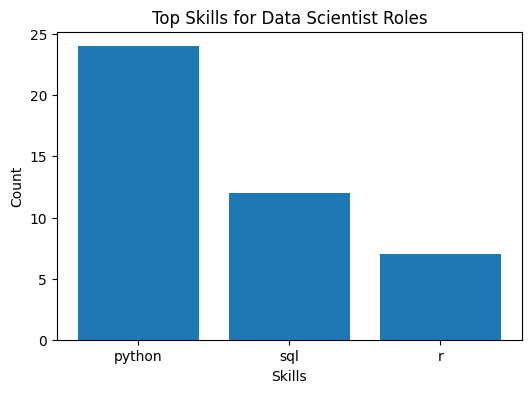

In [22]:
import matplotlib.pyplot as plt

x = data_scientist_skills['extracted_skills']
y = data_scientist_skills['count']

plt.figure(figsize=(6,4))

plt.bar(x,y)

plt.xlabel('Skills')
plt.ylabel('Count')
plt.title('Top Skills for Data Scientist Roles')
plt.show()

## 2.2 Automating Role-Based Skill Visualizations

### Observation

- The visualization workflow was generalized using a reusable plotting function, allowing role-based charts to be generated dynamically for multiple NLP categories.
- This approach improves scalability, reduces repetitive plotting code, and makes the visualization pipeline easier to maintain.
- The generated charts clearly highlight differences in technical demand across job roles.
- SQL appears more dominant in Data Analyst positions, while Python is significantly more dominant in Data Scientist roles.
- Automating the visualization process improves analytical consistency across skills, tools, and technologies.

In [23]:
def plot_role_distribution(dataframe, column_name, category_name, metric_column, y_label):

    job_roles = dataframe['standardized_job_title'].unique()

    for role in job_roles:
        filtered_df = dataframe[
            dataframe['standardized_job_title'] == role]

        x = filtered_df[column_name]
        y = filtered_df[metric_column]

        plt.figure(figsize=(6,4))

        bar = plt.bar(x,y)
        plt.bar_label(bar)

        plt.xlabel(category_name)
        plt.ylabel(y_label)
        plt.title(f'Relative {category_name} Demand for {role.title()} Roles')
        plt.show()                                                  

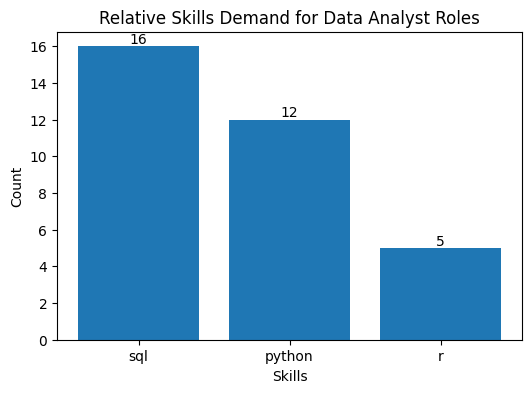

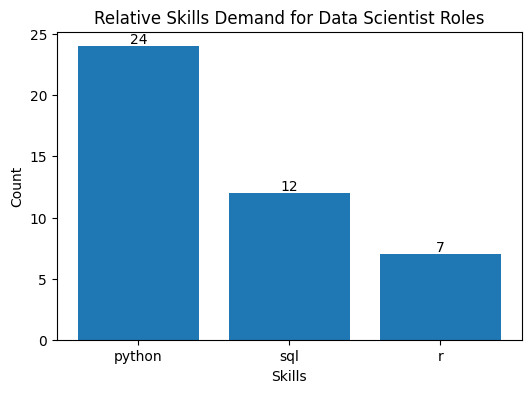

In [24]:
plot_role_distribution(top_skills_df, 'extracted_skills', 'Skills', 'count', 'Count')

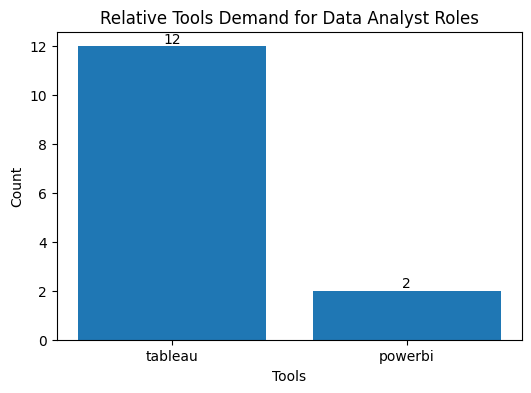

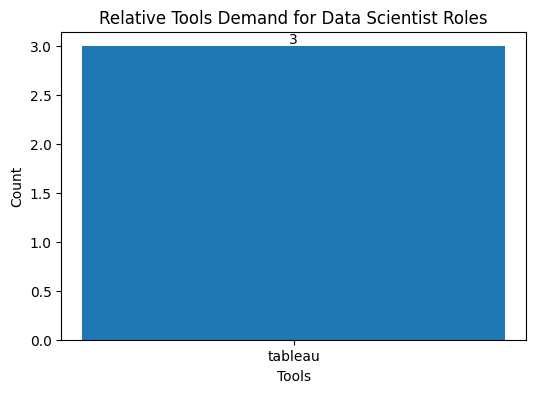

In [25]:
plot_role_distribution(top_tools_df, 'extracted_tools', 'Tools', 'count','Count')

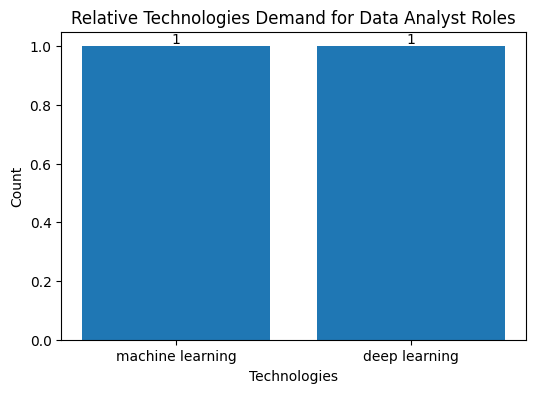

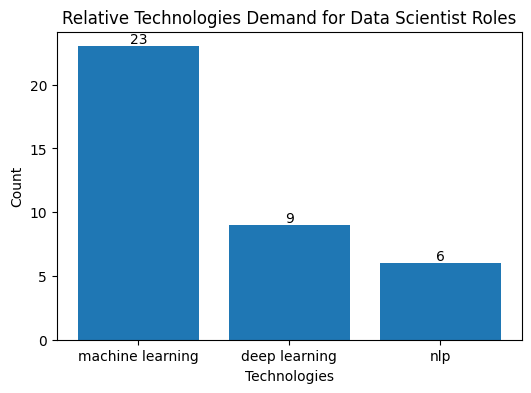

In [26]:
plot_role_distribution(top_technologies_df, 'extracted_technologies', 'Technologies', 'count', 'Count')

## 2.5 Comparing Relative Skill Demand Across Roles

In [27]:
job_role_counts = df['standardized_job_title'].value_counts()
job_role_counts

standardized_job_title
data scientist    28
data analyst      26
Name: count, dtype: int64

In [28]:
job_role_counts.to_frame().reset_index()

,standardized_job_title,count
0,data scientist,28
1,data analyst,26


In [29]:
merged_skills_df = pd.merge(job_role_counts, top_skills_df, on='standardized_job_title')
merged_skills_df = merged_skills_df.rename(columns={
    'count_x': 'total_postings',
    'count_y': 'skill_count'
})
merged_skills_df['skill_percentage'] = (
    merged_skills_df['skill_count'] / merged_skills_df['total_postings']
) * 100

merged_skills_df

,standardized_job_title,total_postings,extracted_skills,skill_count,skill_percentage
0,data scientist,28,python,24,85.714286
1,data scientist,28,sql,12,42.857143
2,data scientist,28,r,7,25.000000
3,data analyst,26,sql,16,61.538462
4,data analyst,26,python,12,46.153846
5,data analyst,26,r,5,19.230769


In [30]:
merged_tools_df = pd.merge(job_role_counts, top_tools_df, on='standardized_job_title')
merged_tools_df = merged_tools_df.rename(columns={
    'count_x': 'total_postings',
    'count_y': 'tool_count'
})
merged_tools_df['tools_percentage'] = (
    merged_tools_df['tool_count'] / merged_tools_df['total_postings']
) * 100
merged_tools_df

,standardized_job_title,total_postings,extracted_tools,tool_count,tools_percentage
0,data scientist,28,tableau,3,10.714286
1,data analyst,26,tableau,12,46.153846
2,data analyst,26,powerbi,2,7.692308


In [31]:
merged_technologies_df = pd.merge(job_role_counts, top_technologies_df, on='standardized_job_title')
merged_technologies_df = merged_technologies_df.rename(columns={
    'count_x': 'total_postings',
    'count_y': 'technologies_count'
})
merged_technologies_df['technology_percentage'] = (
    merged_technologies_df['technologies_count'] / merged_technologies_df['total_postings']
) * 100
merged_technologies_df

,standardized_job_title,total_postings,extracted_technologies,technologies_count,technology_percentage
0,data scientist,28,machine learning,23,82.142857
1,data scientist,28,deep learning,9,32.142857
2,data scientist,28,nlp,6,21.428571
3,data analyst,26,machine learning,1,3.846154
4,data analyst,26,deep learning,1,3.846154


## 2.6 Visualizing Relative Skill Demand by Percentage

### Observation

- Percentage-based visualization provides a normalized comparison of skill demand across job roles.
- Python appears in a significantly higher percentage of Data Scientist job postings, while SQL is more dominant within Data Analyst roles.
- Relative demand analysis reduces bias caused by differences in the total number of postings between roles.
- Normalized skill percentages provide a more reliable representation of role-specific technical requirements compared to raw frequency counts alone.

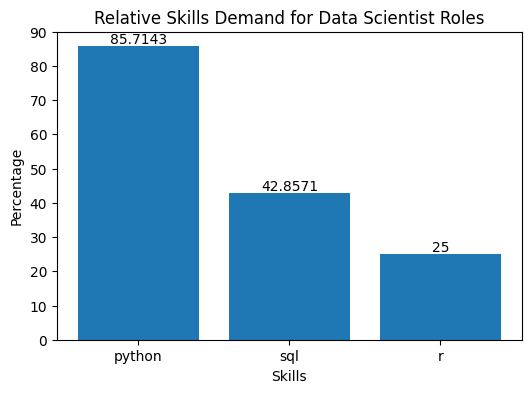

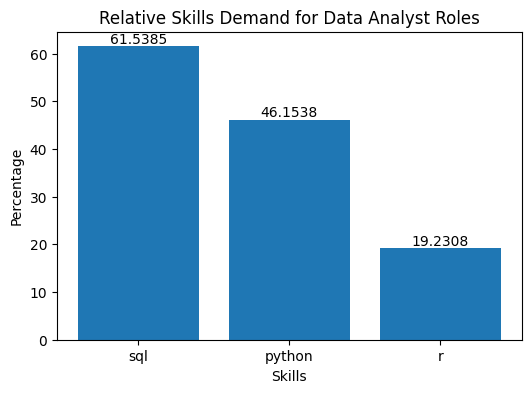

In [32]:
plot_role_distribution(merged_skills_df, 'extracted_skills', 'Skills', 'skill_percentage', 'Percentage')

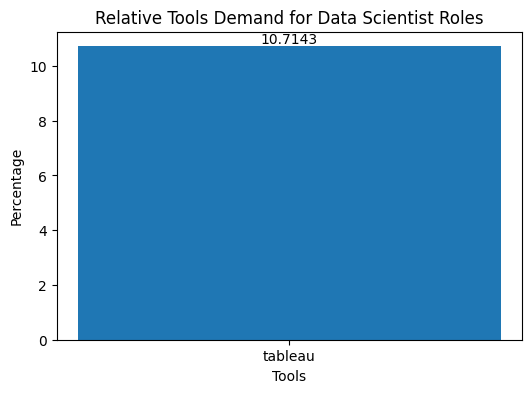

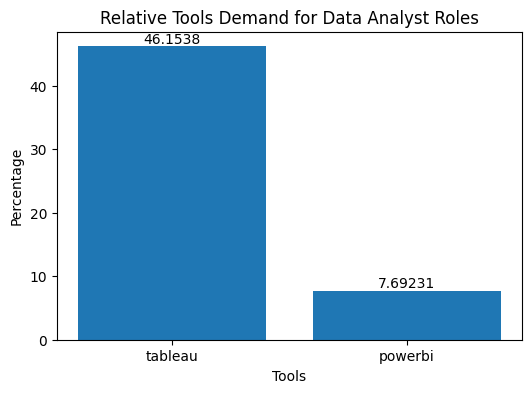

In [33]:
plot_role_distribution(merged_tools_df, 'extracted_tools', 'Tools', 'tools_percentage', 'Percentage')

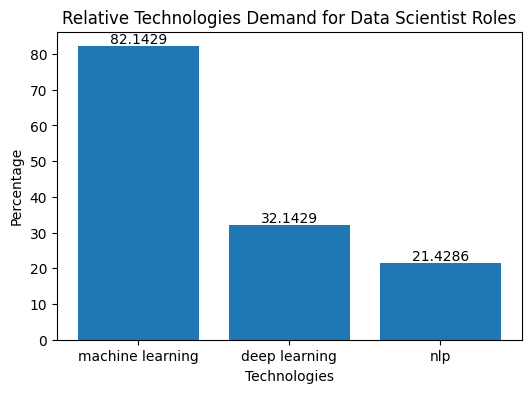

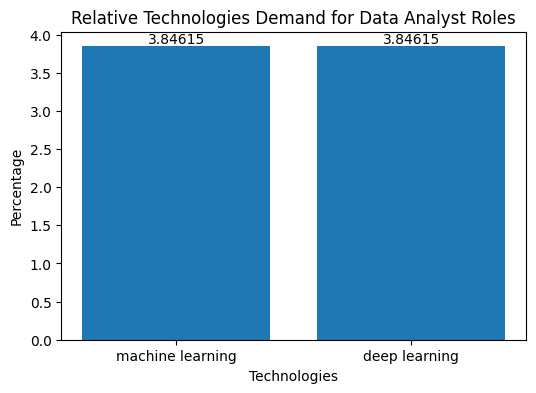

In [34]:
plot_role_distribution(merged_technologies_df, 'extracted_technologies', 'Technologies', 'technology_percentage', 'Percentage')

## 2.7 Comparing Skills, Tools, and Technologies Holistically

### Observation

- Skills, tools, and technologies were standardized into a unified analytical structure and combined into a single competency profile dataset.
- Schema standardization enabled multiple NLP extraction categories to be integrated consistently using a long-format tabular structure.
- The unified competency dataset provides a more holistic view of the technical requirements associated with each job role.
- Combining multiple competency categories improves downstream analysis, comparison, and visualization workflows.

In [35]:
skills_profile = merged_skills_df[
    [
        'standardized_job_title',
        'extracted_skills',
        'skill_percentage'
    ]
].rename(columns={
    'extracted_skills': 'term',
    'skill_percentage': 'percentage'
})

skills_profile['category'] = 'Skill'

skills_profile

,standardized_job_title,term,percentage,category
0,data scientist,python,85.714286,Skill
1,data scientist,sql,42.857143,Skill
2,data scientist,r,25.000000,Skill
3,data analyst,sql,61.538462,Skill
4,data analyst,python,46.153846,Skill
5,data analyst,r,19.230769,Skill


In [36]:
tools_profile = merged_tools_df[
    [
        'standardized_job_title',
        'extracted_tools',
        'tools_percentage'
    ]
].rename(columns={
    'extracted_tools': 'term',
    'tools_percentage': 'percentage'
})

tools_profile['category'] = 'Tool'
tools_profile

,standardized_job_title,term,percentage,category
0,data scientist,tableau,10.714286,Tool
1,data analyst,tableau,46.153846,Tool
2,data analyst,powerbi,7.692308,Tool


In [37]:
technology_profile = merged_technologies_df[
    [
        'standardized_job_title',
        'extracted_technologies',
        'technology_percentage'
    ]
].rename(columns={
    'extracted_technologies': 'term',
    'technology_percentage': 'percentage'
})

technology_profile['category'] = 'Technology'
technology_profile

,standardized_job_title,term,percentage,category
0,data scientist,machine learning,82.142857,Technology
1,data scientist,deep learning,32.142857,Technology
2,data scientist,nlp,21.428571,Technology
3,data analyst,machine learning,3.846154,Technology
4,data analyst,deep learning,3.846154,Technology


In [38]:
role_competency_profile = pd.concat([skills_profile, tools_profile, technology_profile], axis=0, ignore_index=True)
role_competency_profile

,standardized_job_title,term,percentage,category
0,data scientist,python,85.714286,Skill
1,data scientist,sql,42.857143,Skill
2,data scientist,r,25.000000,Skill
3,data analyst,sql,61.538462,Skill
4,data analyst,python,46.153846,Skill
5,data analyst,r,19.230769,Skill
6,data scientist,tableau,10.714286,Tool
7,data analyst,tableau,46.153846,Tool
8,data analyst,powerbi,7.692308,Tool
9,data scientist,machine learning,82.142857,Technology


In [39]:
role_competency_profile['category'].value_counts()

category
Skill         6
Technology    5
Tool          3
Name: count, dtype: int64

## 2.8 Exploring Competency Composition by Role

In [40]:
role_competency_profile

,standardized_job_title,term,percentage,category
0,data scientist,python,85.714286,Skill
1,data scientist,sql,42.857143,Skill
2,data scientist,r,25.000000,Skill
3,data analyst,sql,61.538462,Skill
4,data analyst,python,46.153846,Skill
5,data analyst,r,19.230769,Skill
6,data scientist,tableau,10.714286,Tool
7,data analyst,tableau,46.153846,Tool
8,data analyst,powerbi,7.692308,Tool
9,data scientist,machine learning,82.142857,Technology


In [41]:
role_category_summary = role_competency_profile.groupby(['standardized_job_title', 'category'])['percentage'].sum().reset_index()
role_category_summary

,standardized_job_title,category,percentage
0,data analyst,Skill,126.923077
1,data analyst,Technology,7.692308
2,data analyst,Tool,53.846154
3,data scientist,Skill,153.571429
4,data scientist,Technology,135.714286
5,data scientist,Tool,10.714286


### Observation

- Both Data Scientist and Data Analyst roles show high cumulative intensity in core technical skills.
- Data Scientist roles demonstrate significantly higher technology-related intensity, reflecting stronger association with Machine Learning and NLP domains.
- Data Analyst roles show substantially higher tool-related intensity, indicating greater emphasis on reporting and visualization platforms such as Tableau.
- The grouped comparison clearly highlights the specialization differences between analytical and machine learning-oriented career paths.

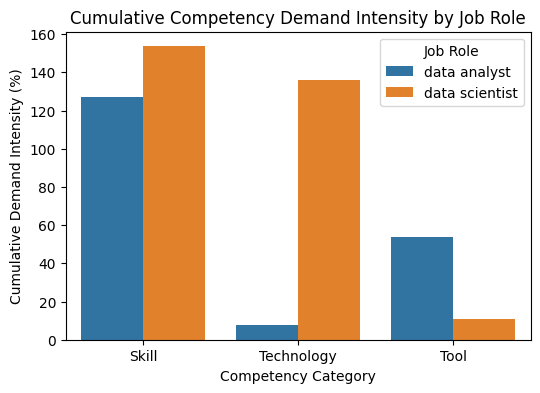

In [42]:
import seaborn as sns

plt.figure(figsize=(6,4))
sns.barplot(data = role_category_summary,
            x='category',
            y='percentage',
            hue='standardized_job_title')

plt.xlabel('Competency Category')
plt.ylabel('Cumulative Demand Intensity (%)')
plt.legend(title='Job Role')
plt.title('Cumulative Competency Demand Intensity by Job Role')

plt.show()

## 2.9 Summarizing Key NLP Market Intelligence Insights

### Key Insights

- SQL is the dominant skill for Data Analyst roles, appearing in approximately 61% of the analyzed job postings.
- Python is the dominant skill for Data Scientist roles, appearing in approximately 86% of the analyzed postings.
- Data Scientist roles demonstrate significantly higher technology-related competency intensity, particularly in Machine Learning and NLP domains.
- Data Analyst roles show stronger emphasis on tool-oriented competencies such as Tableau and reporting-related platforms.
- Percentage-based analysis provides a more reliable comparison than raw counts because it normalizes demand relative to the total number of postings per role.
- Relative demand analysis improves interpretation by showing how frequently competencies appear within each job category rather than relying only on absolute occurrence counts.